In [1]:
import sys
import numpy as np
import scipy
import pandas as pd
import matplotlib.pyplot as plt

print("Python interpreter:", sys.executable)
print("Notebook environment is ready!")

Python interpreter: /Users/shreyagokhale/Desktop/Docs/Documents/Research projects_cybersecurity/novaflow-fair-crq/.venv/bin/python
Notebook environment is ready!


In [ ]:
#Imports

import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

# Find the project root when running from VS Code/Jupyter.
cwd = Path.cwd().resolve()
project_root = cwd if (cwd / "config").exists() else cwd.parent

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from config.model_config import get_config
from src.distributions import sample_distribution, distribution_mean, inverse_cdf

config = get_config()
rng = np.random.default_rng(42)

print("Project:", project_root)
print("Configuration loaded.")

Project: /Users/shreyagokhale/Desktop/Docs/Documents/Research projects_cybersecurity/novaflow-fair-crq
Configuration loaded.


Theoretical mean: 350.00 hours
Simulated mean:   349.40 hours
Simulated median: 337.35 hours


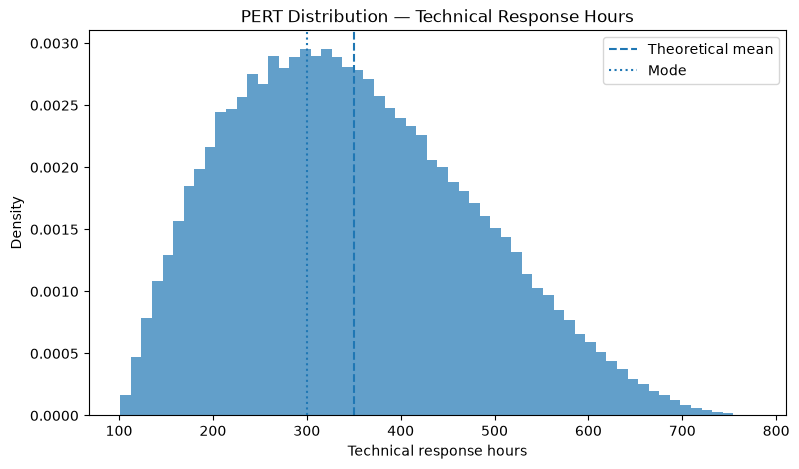

In [ ]:
#Simulate technical response hours

spec = config["primary_response"]["technical_response_hours"]

draws = sample_distribution(spec, rng, size=100_000)

print(f"Theoretical mean: {distribution_mean(spec):.2f} hours")
print(f"Simulated mean:   {np.mean(draws):.2f} hours")
print(f"Simulated median: {np.median(draws):.2f} hours")

plt.figure(figsize=(9, 5))
plt.hist(draws, bins=60, density=True, alpha=0.7)
plt.axvline(distribution_mean(spec), linestyle="--",
            label="Theoretical mean")
plt.axvline(spec["mode"], linestyle=":",
            label="Mode")
plt.xlabel("Technical response hours")
plt.ylabel("Density")
plt.title("PERT Distribution — Technical Response Hours")
plt.legend()
plt.show()

#Should see a distribution concentrated around 300–400 hours, with bounds at 100 and 800.

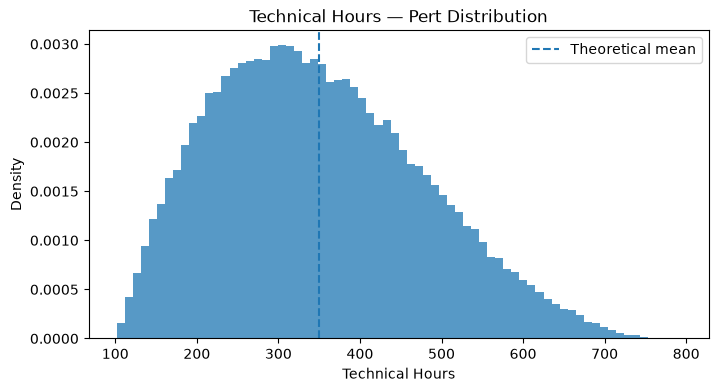

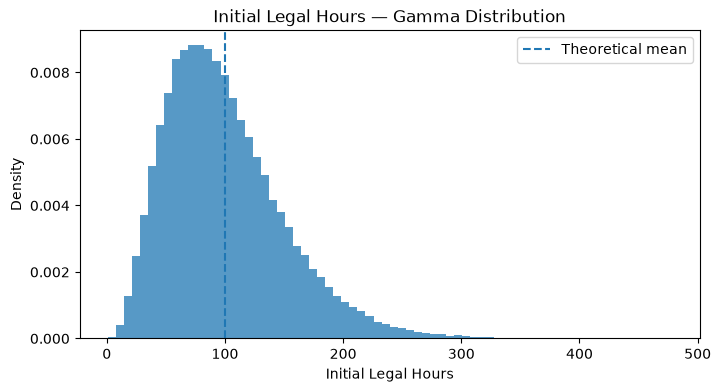

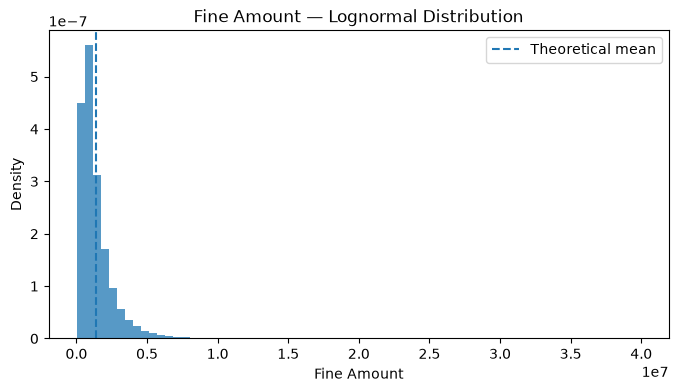

In [ ]:
#Compare three important distributions

examples = [
    ("Technical Hours", config["primary_response"]["technical_response_hours"]),
    ("Initial Legal Hours", config["secondary_response"]["legal"]["stages"]["initial_triage"]["outside_hours"]),
    ("Fine Amount", config["fines_and_judgments"]["regulatory_fine"]["amount_if_fined_usd"]),
]

for name, spec in examples:
    values = sample_distribution(spec, rng, size=100_000)

    plt.figure(figsize=(8, 4))
    plt.hist(values, bins=70, density=True, alpha=0.75)
    plt.axvline(distribution_mean(spec), linestyle="--",
                label="Theoretical mean")
    plt.title(f"{name} — {spec['family'].title()} Distribution")
    plt.xlabel(name)
    plt.ylabel("Density")
    plt.legend()
    plt.show()

    #generates separate charts for PERT, Gamma, and Lognormal distributions.
    #Lognormal fine distribution has a long right tail. That is important for modeling potentially large financial losses.

Direct sample mean: 349.91
Inverse CDF mean:   349.0
Theoretical mean:   350.0


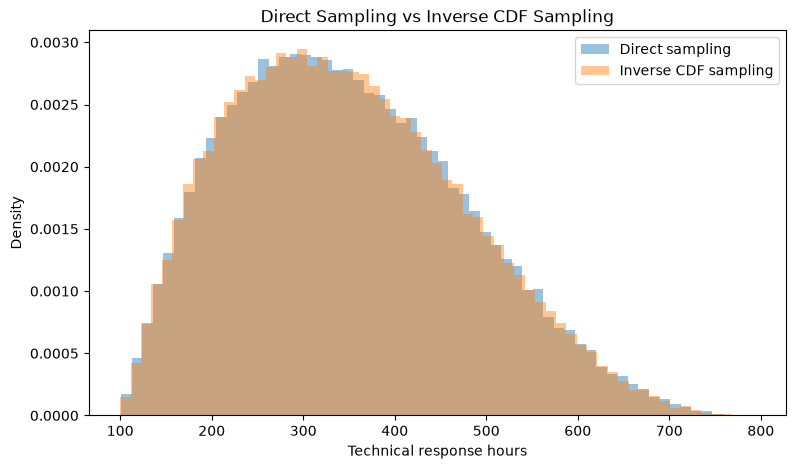

In [ ]:
from scipy.stats import norm

spec = config["primary_response"]["technical_response_hours"]

# Method 1: Direct random sampling
rng_direct = np.random.default_rng(123)
direct = sample_distribution(spec, rng_direct, size=100_000)

# Method 2: Standard normal -> Uniform -> Inverse CDF
rng_copula = np.random.default_rng(456)
z = rng_copula.standard_normal(100_000)
u = norm.cdf(z)
transformed = inverse_cdf(spec, u)

print("Direct sample mean:", round(np.mean(direct), 2))
print("Inverse CDF mean:  ", round(np.mean(transformed), 2))
print("Theoretical mean:  ", round(distribution_mean(spec), 2))

plt.figure(figsize=(9, 5))
plt.hist(direct, bins=60, density=True, alpha=0.45,
         label="Direct sampling")
plt.hist(transformed, bins=60, density=True, alpha=0.45,
         label="Inverse CDF sampling")
plt.xlabel("Technical response hours")
plt.ylabel("Density")
plt.title("Direct Sampling vs Inverse CDF Sampling")
plt.legend()
plt.show()

# The two distributions should overlap closely, and their simulated means should be near 350 hours.
# This is the key validation for the Gaussian copula implementation: transforming standard normal draws through Phi and the inverse marginal CDF preserves the target marginal distribution.